# 4 · Figure 2: classroom networks

This page draws Figure 2 from the analysis datasets prepared in [Data
and measures](01_data_and_measures.ipynb), together with the supplied
drawing coordinates.

# Four layers of one classroom

Figure 2 shows, in one small classroom (9 children), the four networks
the analysis combines:

-   **A. Friendship**: who named whom as a best friend. Green arrows are
    mutual friendships; blue arrows are one-sided.
-   **B. Popularity** and **C. non-popularity**: who named whom as
    popular or as not popular. Social Rank is computed from these two
    layers.
-   **D. Tokens**: every transfer in the game, darker for more tokens.

The same child keeps the same position in all four layers, so one can
follow how a child who is central in one layer fares in the others.

In [ ]:
here::i_am("notebooks/main/04_figure2_classroom_networks.qmd")
library(tidyverse)
library(igraph)
library(ggraph)
library(patchwork)
library(here)
source(here("code", "00_style.R"))

The data are reused if `analysis_dyads` and `analysis_students` are
already in R. Otherwise, this step loads their CSV files from
`data/generated/main/`, or builds them from the raw inputs on first use.

In [ ]:
source(here("code", "00_load_main_data.R"), local = TRUE)
dyads <- analysis_dyads
students <- analysis_students

In [ ]:
main_data_status

dataset,rows,source
analysis_dyads,17804,Saved CSV files
analysis_students,859,Saved CSV files


In [ ]:
example_class <- 16

class_students <- students %>%
  filter(class_id == example_class) %>%
  mutate(name = as.character(student_id),
         sex  = if_else(female == 1, "Female", "Male"))

class_dyads <- dyads %>%
  filter(class_id == example_class) %>%
  mutate(from = as.character(sender_id), to = as.character(receiver_id))

cat("Children in the classroom:", nrow(class_students), "\n")   # 9
cat("Directed pairs:          ", nrow(class_dyads), "\n")      # 72 = 9 x 8

In [ ]:
tibble(children = nrow(class_students), directed_decisions = nrow(class_dyads))

children,directed_decisions
9,72


To draw the four panels, we first fix one position for each child,
computed on the network that joins all four layers.

In [ ]:
# One layout for all panels. We compute it on the network that joins all
# four layers, so every child is placed close to the classmates she is
# connected with in any of them. The seed fixes the result.

all_links <- class_dyads %>%
  filter(nom_q3 == 1 | nom_q4 == 1 | nom_q5 == 1 | tokens_sent > 0)

set.seed(16)
layout_all <- graph_from_data_frame(all_links %>% select(from, to),
                                    vertices = class_students %>% select(name)) %>%
  layout_with_fr()

node_positions <- tibble(name = class_students$name,
                         x = layout_all[, 1], y = layout_all[, 2])

A small function draws one layer; it is called four times.

In [ ]:
# Draws one layer. `links` has columns from, to (and optionally a color group
# or a width); node size is given by `size_var` in the node table.

draw_layer <- function(links, nodes, size_var, size_title, edge_color = "grey40",
                       title = "") {
  network <- graph_from_data_frame(links, vertices = nodes)

  # "manual" layout: each child is drawn at her (x, y) from node_positions
  ggraph(network, layout = "manual", x = V(network)$x, y = V(network)$y) +
    geom_edge_arc(aes(color = I(edge_color_value)), strength = 0.15,
                  arrow = arrow(length = unit(2, "mm"), type = "closed"),
                  end_cap = circle(3.5, "mm"), width = 0.5) +
    geom_node_point(aes(size = .data[[size_var]], fill = sex),
                    shape = 21, color = "grey20") +
    scale_fill_manual(values = c(Female = color_female, Male = color_male)) +
    scale_size_continuous(range = c(2, 9)) +
    guides(fill = guide_legend(override.aes = list(size = 4))) +
    coord_fixed(xlim = range(node_positions$x) + c(-0.3, 0.3),
                ylim = range(node_positions$y) + c(-0.3, 0.3)) +
    labs(title = title, size = size_title, fill = "Sex") +
    theme_void() +
    theme(plot.title = element_text(face = "bold"),
          legend.position = "right",
          legend.key.size = unit(3, "mm"),
          legend.text = element_text(size = 7),
          legend.title = element_text(size = 8))
}

Node size is the number of nominations received in A–C and the number of
tokens received in D.

In [ ]:
# Nominations received in each question (in-degree) give the node size in A-C
in_degree <- function(question) {
  class_dyads %>%
    group_by(name = to) %>%
    summarise(value = sum(.data[[question]]))
}

nodes <- class_students %>%
  select(name, sex) %>%
  left_join(node_positions, by = "name") %>%
  left_join(in_degree("nom_q3") %>% rename(friend_in = value),   by = "name") %>%
  left_join(in_degree("nom_q4") %>% rename(popular_in = value),  by = "name") %>%
  left_join(in_degree("nom_q5") %>% rename(unpopular_in = value), by = "name") %>%
  left_join(class_dyads %>% group_by(name = to) %>%
              summarise(tokens_in = sum(tokens_sent)), by = "name")

## A. Friendship nominations

In [ ]:
# A. Friendship: green if the nomination is mutual, blue if one-way
friend_links <- class_dyads %>%
  filter(nom_q3 == 1) %>%
  left_join(class_dyads %>% select(from = to, to = from, back = nom_q3),
            by = c("from", "to")) %>%
  transmute(from, to,
            edge_color_value = if_else(back == 1, color_mutual, color_asymmetric))

panel_a <- draw_layer(friend_links, nodes, "friend_in", "Nominations\nreceived",
                      title = "A. Friendship nominations")

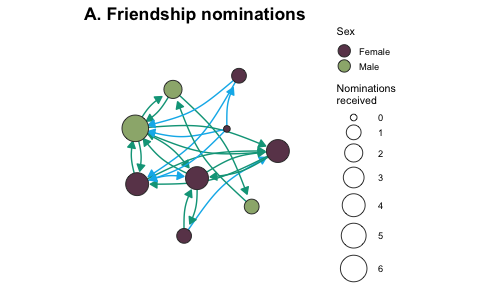

In [ ]:
panel_a

## B. Popularity nominations

In [ ]:
# B. Popularity: grey arrows
popular_links <- class_dyads %>%
  filter(nom_q4 == 1) %>%
  transmute(from, to, edge_color_value = "grey40")

panel_b <- draw_layer(popular_links, nodes, "popular_in", "Nominations\nreceived",
                      title = "B. Popularity nominations")

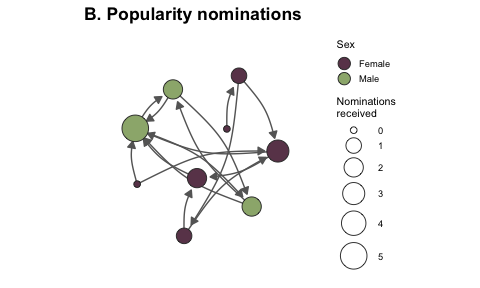

In [ ]:
panel_b

## C. Non-popularity nominations

In [ ]:
# C. Non-popularity: grey arrows
unpopular_links <- class_dyads %>%
  filter(nom_q5 == 1) %>%
  transmute(from, to, edge_color_value = "grey40")

panel_c <- draw_layer(unpopular_links, nodes, "unpopular_in", "Nominations\nreceived",
                      title = "C. Non-popularity nominations")

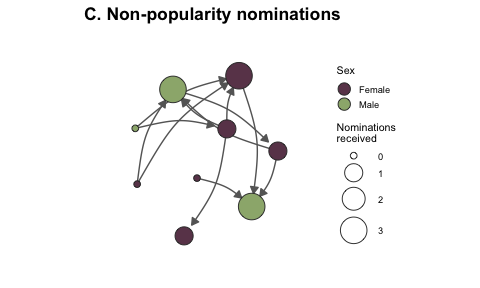

In [ ]:
panel_c

## D. Token transfers

In [ ]:
# D. Tokens: one arrow per transfer of at least one token; darker = more tokens
token_links <- class_dyads %>%
  filter(tokens_sent > 0) %>%
  transmute(from, to,
            edge_color_value = grey(1 - 0.08 * tokens_sent - 0.1))  # 1 token light, 10 dark

panel_d <- draw_layer(token_links, nodes, "tokens_in", "Tokens\nreceived",
                      title = "D. Token transfers in the game")

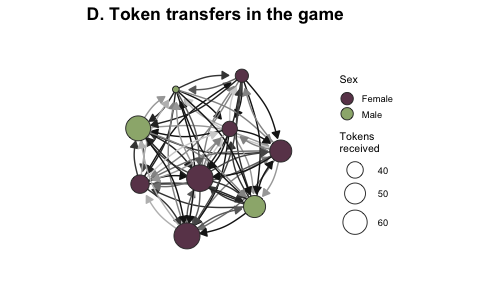

In [ ]:
panel_d

## The assembled figure

The published figure shows the same four layers as tilted planes stacked
on top of each other, with one legend. The node positions are the ones
chosen for that drawing (`data/raw/figure2_layout.csv`); they are a
drawing choice and play no role in any calculation. Each plane is the
layout stretched, flattened and slanted.

In [ ]:
# The assembled version of Figure 2 (as in the paper): the four layers are
# drawn as tilted planes stacked on top of each other, with one legend.
#
# The node positions are the ones chosen for the paper (data/raw/figure2_layout.csv,
# a drawing choice only). Each layer is then "tilted": a point (x, y) of a
# layer is drawn at
#
#     X = width * x + tilt * y  (stretch, and shift right when higher up)
#     Y = height * y + center   (flatten and move the plane to its row)

paper_layout <- read_csv(here("data", "raw", "figure2_layout.csv"), show_col_types = FALSE) %>%
  mutate(name = as.character(student_id))

width  <- 1.55   # how wide the planes are
tilt   <- 0.25   # how slanted the planes are
height <- 0.36   # how flat the planes are
layers <- tibble(
  layer  = c("A", "B", "C", "D"),
  title  = c("A. Friendship nominations", "B. Popularity nominations",
             "C. Non-popularity nominations", "D. Token transfers in the game"),
  center = c(4.05, 2.7, 1.35, 0),                         # rows, from top to bottom
  color  = c(color_mutual, "#1F3A5F", "#C95A3A", "grey20")
)

to_screen <- function(x, y, layer_center) {
  tibble(X = width * x + tilt * y, Y = height * y + layer_center)
}

# Frame of each plane: the rectangle [-1.2, 1.2] x [-1.3, 1.3], tilted
frames <- layers %>%
  rowwise() %>%
  reframe(layer, color,
          to_screen(c(-1.2, 1.2, 1.2, -1.2), c(-1.3, -1.3, 1.3, 1.3), center))

Nodes and arrows of the four planes. Mutual friendships are drawn once,
with two heads.

In [ ]:
# Nodes of the four layers, with their size: nominations received in A-C and
# tokens received in D (point size grows with the square root, as an area)
node_size <- function(value, max_value) 1.5 + 5 * sqrt(value / max_value)

layer_nodes <- nodes %>%
  select(name, sex, A = friend_in, B = popular_in, C = unpopular_in, D = tokens_in) %>%
  pivot_longer(A:D, names_to = "layer", values_to = "value") %>%
  left_join(paper_layout %>% select(name, x, y), by = "name") %>%
  left_join(layers, by = "layer") %>%
  group_by(layer) %>%
  mutate(size = if_else(layer == "D", node_size(value, 70), node_size(value, max(value)))) %>%
  ungroup() %>%
  mutate(to_screen(x, y, center))

# Arrows of the four layers. In A, a mutual friendship is drawn once with
# two heads (green); a one-way nomination with one head (blue).
mutual_pairs <- friend_links %>% filter(edge_color_value == color_mutual)

layer_arrows <- bind_rows(
  mutual_pairs %>% filter(from < to) %>% mutate(layer = "A", ends = "both"),
  friend_links %>% filter(edge_color_value != color_mutual) %>% mutate(layer = "A", ends = "last"),
  popular_links   %>% mutate(layer = "B", ends = "last"),
  unpopular_links %>% mutate(layer = "C", ends = "last"),
  token_links     %>% mutate(layer = "D", ends = "last")
) %>%
  left_join(paper_layout %>% select(from = name, x0 = x, y0 = y), by = "from") %>%
  left_join(paper_layout %>% select(to = name, x1 = x, y1 = y), by = "to") %>%
  left_join(layers %>% select(layer, center), by = "layer") %>%
  # stop the arrows a little before the nodes
  mutate(x0s = x0 + 0.12 * (x1 - x0), y0s = y0 + 0.12 * (y1 - y0),
         x1s = x1 - 0.12 * (x1 - x0), y1s = y1 - 0.12 * (y1 - y0),
         X0 = width * x0s + tilt * y0s, Y0 = height * y0s + center,
         X1 = width * x1s + tilt * y1s, Y1 = height * y1s + center)

In [ ]:
# The legend is drawn under the bottom plane, in the same coordinates
legend_y <- -0.8
sex_key   <- tibble(X = -1.9, Y = legend_y - c(0.25, 0.45), sex = c("Female", "Male"))
size_key  <- tibble(X = 0.55, Y = legend_y - c(0.38, 0.6, 0.86), tokens = c(30, 50, 70)) %>%
  mutate(size = node_size(tokens, 70))
gray_key  <- tibble(X = 1.55, Y = legend_y - c(0.38, 0.6, 0.82), tokens = c(1, 5, 10)) %>%
  mutate(color = grey(1 - 0.08 * tokens - 0.1))

In [ ]:
arrow_head <- arrow(length = unit(1.1, "mm"), type = "closed")

figure2_assembled <- ggplot() +
  # planes and titles
  geom_polygon(data = frames, aes(X, Y, group = layer, color = I(color)),
               fill = "white", linewidth = 0.6) +
  geom_text(data = layers, aes(x = -1.75, y = center + 0.66, label = title, color = I(color)),
            hjust = 0, fontface = "bold", size = 3.4) +
  # arrows (one geom per kind of arrow head)
  geom_curve(data = filter(layer_arrows, ends == "last"),
             aes(x = X0, y = Y0, xend = X1, yend = Y1, color = I(edge_color_value)),
             curvature = 0.15, linewidth = 0.3, arrow = arrow_head) +
  geom_curve(data = filter(layer_arrows, ends == "both"),
             aes(x = X0, y = Y0, xend = X1, yend = Y1, color = I(edge_color_value)),
             curvature = 0.08, linewidth = 0.55,
             arrow = arrow(length = unit(1.1, "mm"), type = "closed", ends = "both")) +
  # children
  geom_point(data = layer_nodes, aes(X, Y, size = I(size), fill = sex),
             shape = 21, color = "grey15", stroke = 0.3) +
  # legend: sex
  annotate("text", x = -1.95, y = legend_y, label = "Sex", hjust = 0, fontface = "bold", size = 2.8) +
  geom_point(data = sex_key, aes(X, Y, fill = sex), shape = 21, size = 2.2, color = "grey15") +
  annotate("text", x = -1.8, y = sex_key$Y, label = sex_key$sex, hjust = 0, size = 2.5) +
  # legend: friendship
  annotate("text", x = -1.05, y = legend_y, label = "Friendship", hjust = 0, fontface = "bold", size = 2.8) +
  annotate("segment", x = -1.05, xend = -0.75, y = legend_y - 0.25, yend = legend_y - 0.25,
           color = color_mutual, linewidth = 0.55,
           arrow = arrow(length = unit(1.1, "mm"), type = "closed", ends = "both")) +
  annotate("segment", x = -1.05, xend = -0.75, y = legend_y - 0.45, yend = legend_y - 0.45,
           color = color_asymmetric, linewidth = 0.3, arrow = arrow_head) +
  annotate("text", x = -0.68, y = legend_y - c(0.25, 0.45), label = c("Mutual", "One-way"),
           hjust = 0, size = 2.5) +
  # legend: tokens received (node size) and tokens sent (gray)
  annotate("text", x = 0.3, y = legend_y, label = "Tokens received", hjust = 0, fontface = "bold", size = 2.8) +
  geom_point(data = size_key, aes(X, Y, size = I(size)), shape = 21, fill = "white", color = "grey15") +
  annotate("text", x = 0.75, y = size_key$Y, label = size_key$tokens, hjust = 0, size = 2.5) +
  annotate("text", x = 0.3, y = legend_y - 0.15, label = "(in-strength)", hjust = 0, size = 2.5) +
  annotate("text", x = 1.35, y = legend_y, label = "Tokens sent", hjust = 0, fontface = "bold", size = 2.8) +
  annotate("text", x = 1.35, y = legend_y - 0.15, label = "(gray intensity)", hjust = 0, size = 2.5) +
  geom_segment(data = gray_key, aes(x = X - 0.2, xend = X + 0.1, y = Y, yend = Y, color = I(color)),
               linewidth = 0.4, arrow = arrow_head) +
  annotate("text", x = 1.75, y = gray_key$Y, label = gray_key$tokens, hjust = 0, size = 2.5) +
  scale_fill_manual(values = c(Female = color_female, Male = color_male), guide = "none") +
  coord_fixed(clip = "off") +
  theme_void()

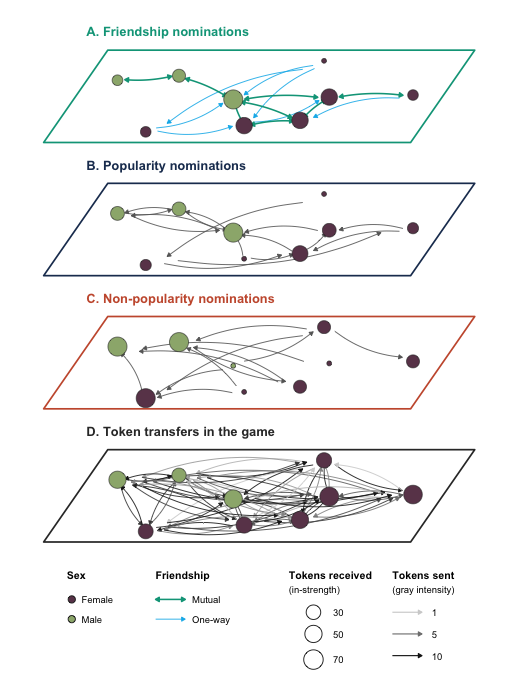

In [ ]:
figure2_assembled

In [ ]:
save_figure(figure2_assembled, "figure2_assembled", width = 5.4, height = 7.2)
save_figure(panel_a, "figure2_panel_A", width = 5, height = 3)
save_figure(panel_b, "figure2_panel_B", width = 5, height = 3)
save_figure(panel_c, "figure2_panel_C", width = 5, height = 3)
save_figure(panel_d, "figure2_panel_D", width = 5, height = 3)

# Session information

In [ ]:
sessionInfo()
## R version 4.3.2 (2023-10-31)
## Platform: aarch64-apple-darwin20 (64-bit)
## Running under: macOS 26.7.1
## 
## Matrix products: default
## BLAS:   /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRblas.0.dylib 
## LAPACK: /Library/Frameworks/R.framework/Versions/4.3-arm64/Resources/lib/libRlapack.dylib;  LAPACK version 3.11.0
## 
## locale:
## [1] C.UTF-8/C.UTF-8/C.UTF-8/C/C.UTF-8/C.UTF-8
## 
## time zone: America/Santiago
## tzcode source: internal
## 
## attached base packages:
## [1] stats     graphics  grDevices utils     datasets  methods   base     
## 
## other attached packages:
##  [1] patchwork_1.3.0 ggraph_2.2.1    igraph_2.1.4    lubridate_1.9.4
##  [5] forcats_1.0.0   stringr_1.5.1   dplyr_1.1.4     purrr_1.0.4    
##  [9] readr_2.1.5     tidyr_1.3.1     tibble_3.2.1    ggplot2_3.5.2  
## [13] tidyverse_2.0.0 here_1.0.1     
## 
## loaded via a namespace (and not attached):
##  [1] gtable_0.3.6       xfun_0.52          ggrepel_0.9.6      tzdb_0.5.0        
##  [5] vctrs_0.6.5        tools_4.3.2        generics_0.1.3     parallel_4.3.2    
##  [9] pkgconfig_2.0.3    lifecycle_1.0.4    compiler_4.3.2     farver_2.1.2      
## [13] textshaping_1.0.0  munsell_0.5.1      ggforce_0.4.2      graphlayouts_1.2.2
## [17] htmltools_0.5.8.1  yaml_2.3.10        pillar_1.10.2      crayon_1.5.3      
## [21] MASS_7.3-60        cachem_1.1.0       viridis_0.6.5      tidyselect_1.2.1  
## [25] digest_0.6.37      stringi_1.8.7      labeling_0.4.3     polyclip_1.10-7   
## [29] rprojroot_2.0.4    fastmap_1.2.0      grid_4.3.2         colorspace_2.1-1  
## [33] cli_3.6.4          magrittr_2.0.3     tidygraph_1.3.1    withr_3.0.2       
## [37] scales_1.3.0       bit64_4.6.0-1      timechange_0.3.0   rmarkdown_2.29    
## [41] bit_4.6.0          gridExtra_2.3      ragg_1.3.3         hms_1.1.3         
## [45] memoise_2.0.1      evaluate_1.0.3     knitr_1.50         viridisLite_0.4.2 
## [49] rlang_1.1.6        Rcpp_1.0.14        glue_1.8.0         tweenr_2.0.3      
## [53] vroom_1.6.5        jsonlite_2.0.0     R6_2.6.1           systemfonts_1.2.2

[Continue to Figure 3A: exchange
patterns](05_figure3a_exchange_patterns.ipynb).